# Is Anyone There? Predicting Room Occupancy for Smarter Energy Use

**PCCoE Pune · Information Technology · SY B.Tech · Semester III · Division B**  
**VSEC Data Science Laboratory · Faculty: JYOTI MANOORKAR · Group B3-4**

| Student | PRN |
|---|---|
| Pratik Deepak Phapale | 125B1F210 |
| Swastik Sandipkumar Phapale | 125B1F212 |
| Nirjar Rupesh Patil | 125B1F206 |

## Aim
Classify a room as empty or occupied from environmental readings, compare four sensor configurations, and demonstrate a transparent hypothetical energy scenario. This notebook contains executed results. It is a single-room research prototype, not a verified campus automation system.

Dataset: Singh, A. & Chaudhari, S. (2018), [Room Occupancy Estimation, UCI](https://doi.org/10.24432/C5P605), CC BY 4.0.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists() and (ROOT.parent / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src.core import load_data, split_data, FEATURES, FEATURE_SETS, simulate_energy
sns.set_theme(style='whitegrid', palette=['#007f73', '#71869b'])
df = load_data()
print('Shape:', df.shape, '| Original source rows:', len(df))
display(df.head())

Shape: (10129, 21) | Original source rows: 10129


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,...,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count,timestamp,occupied
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,...,0.19,0.06,0.06,390,0.769231,0,0,1,2017-12-22 10:49:41,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,...,0.05,0.06,0.06,390,0.646154,0,0,1,2017-12-22 10:50:12,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,...,0.11,0.08,0.06,390,0.519231,0,0,1,2017-12-22 10:50:42,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,...,0.10,0.10,0.09,390,0.388462,0,0,1,2017-12-22 10:51:13,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,...,0.06,0.06,0.06,390,0.253846,0,0,1,2017-12-22 10:51:44,1


## 1. Data audit and preparation

The target `occupied` is 1 when the recorded count is greater than zero. Date and Time are excluded from model inputs. The supplied CO2 slope is also excluded because its sliding-window construction is not verified. The shared loader rejects nonnumeric values, invalid PIR values, missing readings and duplicate timestamps. No source rows are synthetically added or randomly shuffled.

In [2]:
audit = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                      'unique_values': df.nunique()})
display(audit)
print('Exact duplicate rows:', df.duplicated().sum())
print('Timestamp span:', df.timestamp.min(), 'to', df.timestamp.max())
display(df.groupby(df.timestamp.dt.date).agg(rows=('occupied','size'), occupied=('occupied','sum')))
display(df[FEATURES].describe().round(2))

,dtype,missing,unique_values
Date,str,0,7
Time,str,0,10129
S1_Temp,float64,0,24
S2_Temp,float64,0,69
S3_Temp,float64,0,29
S4_Temp,float64,0,27
S1_Light,int64,0,68
S2_Light,int64,0,82
S3_Light,int64,0,177
S4_Light,int64,0,75


Exact duplicate rows: 0
Timestamp span: 2017-12-22 10:49:41 to 2018-01-11 09:00:09


,rows,occupied
timestamp,,
2017-12-22,1462,825
2017-12-23,2779,782
2017-12-24,1064,0
2017-12-25,1716,0
2017-12-26,1063,0
2018-01-10,997,294
2018-01-11,1048,0


,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S6_PIR,S7_PIR
count,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00,10129.00
mean,25.45,25.55,25.06,25.75,25.45,26.02,34.25,13.22,0.17,0.12,0.16,0.10,460.86,0.09,0.08
std,0.35,0.59,0.43,0.36,51.01,67.30,58.40,19.60,0.32,0.27,0.41,0.12,199.96,0.29,0.27
min,24.94,24.75,24.44,24.94,0.00,0.00,0.00,0.00,0.06,0.04,0.04,0.05,345.00,0.00,0.00
25%,25.19,25.19,24.69,25.44,0.00,0.00,0.00,0.00,0.07,0.05,0.06,0.06,355.00,0.00,0.00
50%,25.38,25.38,24.94,25.75,0.00,0.00,0.00,0.00,0.08,0.05,0.06,0.08,360.00,0.00,0.00
75%,25.63,25.63,25.38,26.00,12.00,14.00,50.00,22.00,0.08,0.06,0.07,0.10,465.00,0.00,0.00
max,26.38,29.00,26.19,26.56,165.00,258.00,280.00,74.00,3.88,3.44,3.67,3.40,1270.00,1.00,1.00


## 2. Exploratory analysis

The public dataset description mentions four collection days, while the CSV contains seven calendar dates with gaps. We use the actual timestamps. Class imbalance and correlated measurements matter when evaluating performance.

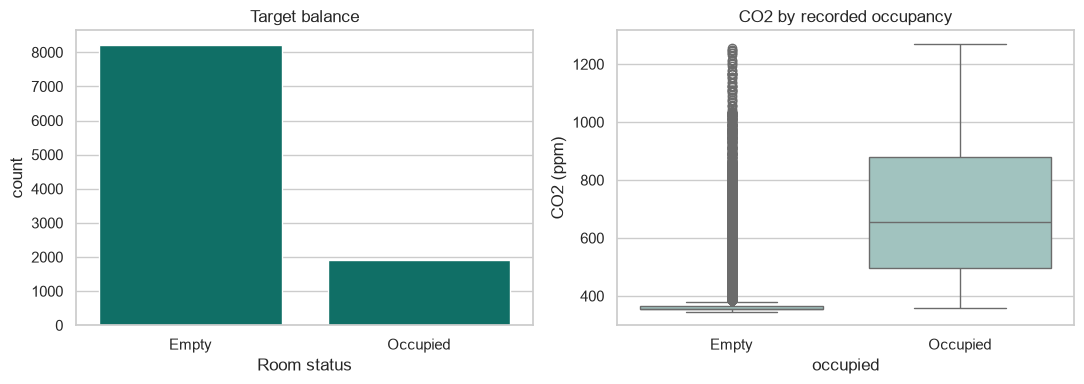

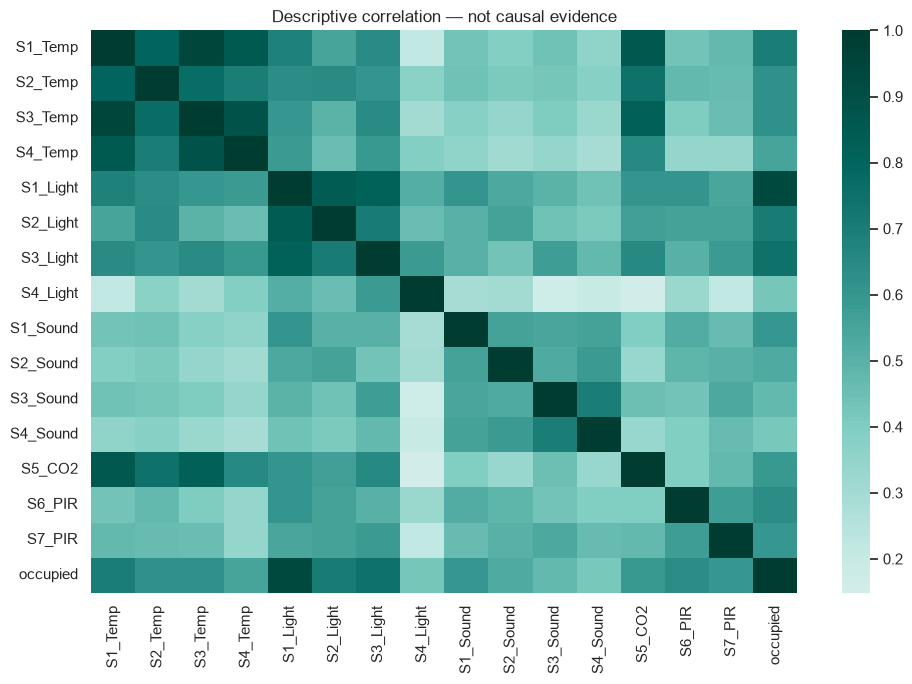

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='occupied', ax=axes[0], color='#007f73')
axes[0].set(xticks=[0,1], xticklabels=['Empty','Occupied'], title='Target balance', xlabel='Room status')
sns.boxplot(data=df, x='occupied', y='S5_CO2', ax=axes[1], color='#9bc9c3')
axes[1].set(xticks=[0,1], xticklabels=['Empty','Occupied'], title='CO2 by recorded occupancy', ylabel='CO2 (ppm)')
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(10,7))
sns.heatmap(df[FEATURES + ['occupied']].corr(), cmap='BrBG', center=0, ax=ax)
ax.set_title('Descriptive correlation — not causal evidence')
plt.tight_layout(); plt.show()

## 3. A statistical question

Is recorded motion associated with occupancy in this sample? We show a contingency table and conditional occupied proportions. A naive chi-square p-value would treat adjacent readings as independent; because the data is temporally correlated, we avoid claiming independent-observation significance.

In [4]:
any_motion = ((df.S6_PIR > 0) | (df.S7_PIR > 0)).astype(int)
table = pd.crosstab(any_motion.rename('Any motion'), df.occupied.rename('Occupied'))
display(table)
display(table.div(table.sum(axis=1), axis=0).round(4))
display(df.groupby('occupied')[['S1_Temp','S1_Light','S5_CO2']].agg(['mean','median','std']).round(2))

Occupied,0,1
Any motion,,
0,8204,727
1,24,1174


Occupied,0,1
Any motion,,
0,0.9186,0.0814
1,0.0200,0.9800


S1_Temp              S1_Light                S5_CO2               
            mean median   std     mean median    std    mean median     std
occupied                                                                   
0          25.34  25.31  0.24     2.69    0.0   5.15  404.45  355.0  136.03
1          25.96  26.06  0.30   123.95  124.0  42.48  705.03  655.0  244.11

## 4. Chronological experimental design

First observed date: training. Second date: validation. Remaining dates: held-out test. All partitions contain both target classes, although later periods are strongly imbalanced. This tests a later period in the same room; it does not establish external-room generalization. No random row split is used.

In [5]:
train, val, test = split_data(df)
splits = pd.DataFrame([{'split': name, 'rows':len(part), 'occupied':int(part.occupied.sum()),
                       'start':part.timestamp.min(), 'end':part.timestamp.max()}
                      for name, part in [('Training',train),('Validation',val),('Test',test)]])
display(splits)
assert train.timestamp.max() < val.timestamp.min()
assert val.timestamp.max() < test.timestamp.min()
display(pd.DataFrame([{'sensor_set':k,'readings':len(v),'columns':', '.join(v)} for k,v in FEATURE_SETS.items()]))

,split,rows,occupied,start,end
0,Training,1462,825,2017-12-22 10:49:41,2017-12-22 23:59:33
1,Validation,2779,782,2017-12-23 00:00:34,2017-12-23 23:59:54
2,Test,5888,294,2017-12-24 00:00:56,2018-01-11 09:00:09


,sensor_set,readings,columns
0,All sensors,15,"S1_Temp, S2_Temp, S3_Temp, S4_Temp, S1_Light, ..."
1,Ambient only,9,"S1_Temp, S2_Temp, S3_Temp, S4_Temp, S1_Light, ..."
2,Three readings,3,"S1_Temp, S1_Light, S5_CO2"
3,Motion only,2,"S6_PIR, S7_PIR"


## 5. Train and compare models

We compare Logistic Regression (with training-only standardization), Decision Tree and Random Forest. Hyperparameters and random seed 42 are fixed in `train.py`. Every algorithm is tested with four sensor sets. Configuration selection uses validation F1, then occupied recall, fewer readings and algorithm name. The threshold remains 0.5.

After selecting the configuration, it is refit using train + validation. Test results are opened only after this choice. All test comparisons are descriptive and must not be used for further tuning. A majority baseline exposes the limitations of accuracy.

For positive class **occupied**: precision = TP/(TP+FP), recall = TP/(TP+FN), F1 = 2PR/(P+R). A false-empty prediction is FN and is especially relevant to energy-management decisions.

In [6]:
from train import run_training
summary = run_training()
validation = pd.read_csv(ROOT / 'reports/validation_comparison.csv')
display(validation[['sensor_set','algorithm','readings','accuracy','precision','recall','f1','false_empty']].round(4))
print('Frozen choice:', summary['selected_algorithm'], '/', summary['selected_sensor_set'])

{
  "selected": [
    "Decision Tree",
    "Three readings"
  ],
  "test": {
    "accuracy": 0.96875,
    "balanced_accuracy": 0.6870748299319728,
    "precision": 1.0,
    "recall": 0.3741496598639456,
    "f1": 0.5445544554455446,
    "roc_auc": 0.6870748299319728,
    "average_precision": 0.4053996598639456,
    "true_empty": 5594,
    "false_occupied": 0,
    "false_empty": 184,
    "true_occupied": 110
  },
  "splits": {
    "train": {
      "rows": 1462,
      "occupied_rows": 825,
      "start": "2017-12-22 10:49:41",
      "end": "2017-12-22 23:59:33"
    },
    "validation": {
      "rows": 2779,
      "occupied_rows": 782,
      "start": "2017-12-23 00:00:34",
      "end": "2017-12-23 23:59:54"
    },
    "test": {
      "rows": 5888,
      "occupied_rows": 294,
      "start": "2017-12-24 00:00:56",
      "end": "2018-01-11 09:00:09"
    }
  }
}


,sensor_set,algorithm,readings,accuracy,precision,recall,f1,false_empty
0,Three readings,Decision Tree,3,0.9996,0.9987,1.0000,0.9994,0
1,Three readings,Logistic Regression,3,0.9996,0.9987,1.0000,0.9994,0
2,Three readings,Random Forest,3,0.9996,0.9987,1.0000,0.9994,0
3,Ambient only,Decision Tree,9,0.9996,0.9987,1.0000,0.9994,0
4,Ambient only,Logistic Regression,9,0.9996,0.9987,1.0000,0.9994,0
5,Ambient only,Random Forest,9,0.9996,0.9987,1.0000,0.9994,0
6,All sensors,Decision Tree,15,0.9996,0.9987,1.0000,0.9994,0
7,All sensors,Random Forest,15,0.9996,0.9987,1.0000,0.9994,0
8,All sensors,Logistic Regression,15,0.9989,0.9962,1.0000,0.9981,0
9,Motion only,Decision Tree,2,0.8485,0.9713,0.4757,0.6386,410


Frozen choice: Decision Tree / Three readings


## 6. Held-out evaluation

Inspect false-empty counts and occupied recall alongside accuracy. The same-room test is not a measure of performance in new classrooms. Classifier scores are not assumed to be calibrated probabilities.

,Selected model,Majority baseline
accuracy,0.9688,0.9501
balanced_accuracy,0.6871,0.5000
precision,1.0000,0.0000
recall,0.3741,0.0000
f1,0.5446,0.0000
roc_auc,0.6871,0.5000
average_precision,0.4054,0.0499
true_empty,5594.0000,5594.0000
false_occupied,0.0000,0.0000
false_empty,184.0000,294.0000


,date,rows,occupied_rows,accuracy,false_empty,false_occupied
0,2017-12-24,1064,0,1.000000,0,0
1,2017-12-25,1716,0,1.000000,0,0
2,2017-12-26,1063,0,1.000000,0,0
3,2018-01-10,997,294,0.815446,184,0
4,2018-01-11,1048,0,1.000000,0,0


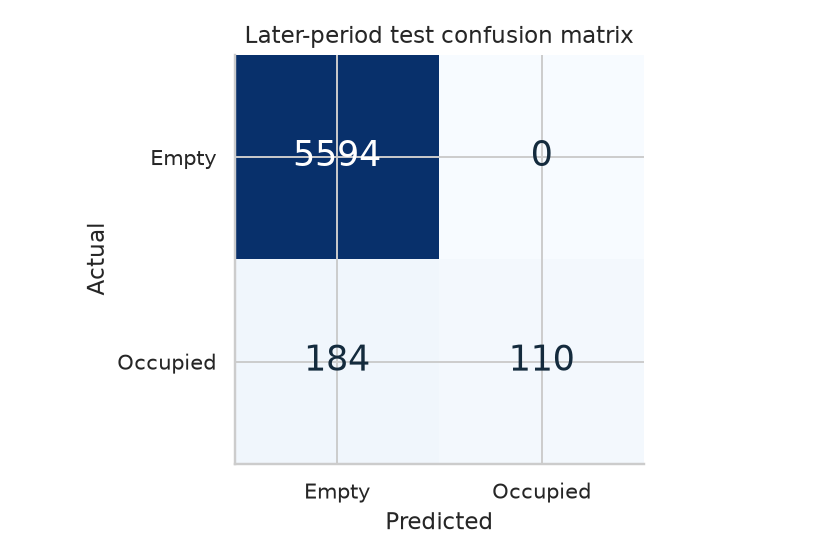

,sensor_set,algorithm,readings,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,true_empty,false_occupied,false_empty,true_occupied
0,All sensors,Logistic Regression,15,0.9688,0.6871,1.0000,0.3741,0.5446,0.9687,0.8090,5594,0,184,110
1,All sensors,Decision Tree,15,0.9688,0.6871,1.0000,0.3741,0.5446,0.8552,0.7175,5594,0,184,110
2,All sensors,Random Forest,15,0.9688,0.6871,1.0000,0.3741,0.5446,0.9612,0.6043,5594,0,184,110
3,Ambient only,Logistic Regression,9,0.9688,0.6871,1.0000,0.3741,0.5446,0.9467,0.5601,5594,0,184,110
4,Ambient only,Decision Tree,9,0.9688,0.6871,1.0000,0.3741,0.5446,0.6871,0.4054,5594,0,184,110
5,Ambient only,Random Forest,9,0.9688,0.6871,1.0000,0.3741,0.5446,0.9336,0.5361,5594,0,184,110
6,Three readings,Logistic Regression,3,0.9688,0.6871,1.0000,0.3741,0.5446,0.9713,0.6976,5594,0,184,110
7,Three readings,Decision Tree,3,0.9688,0.6871,1.0000,0.3741,0.5446,0.6871,0.4054,5594,0,184,110
8,Three readings,Random Forest,3,0.9688,0.6871,1.0000,0.3741,0.5446,0.7488,0.5406,5594,0,184,110
9,Motion only,Logistic Regression,2,0.9885,0.8989,0.9631,0.7993,0.8736,0.8991,0.7938,5585,9,59,235


In [7]:
display(pd.DataFrame({'Selected model':summary['test_metrics'], 'Majority baseline':summary['baseline_metrics']}).round(4))
display(pd.read_csv(ROOT / 'reports/daily_test_metrics.csv'))
from IPython.display import Image
display(Image(filename=str(ROOT / 'reports/figures/confusion_matrix.png')))
display(pd.read_csv(ROOT / 'reports/test_comparison.csv').round(4))

## 7. Do fewer readings preserve performance?

Compare the validation winner for each sensor set. Feature counts are measurement counts, not verified hardware cost. Validation permutation importance uses a model fitted only on training data. Correlated inputs may share importance.

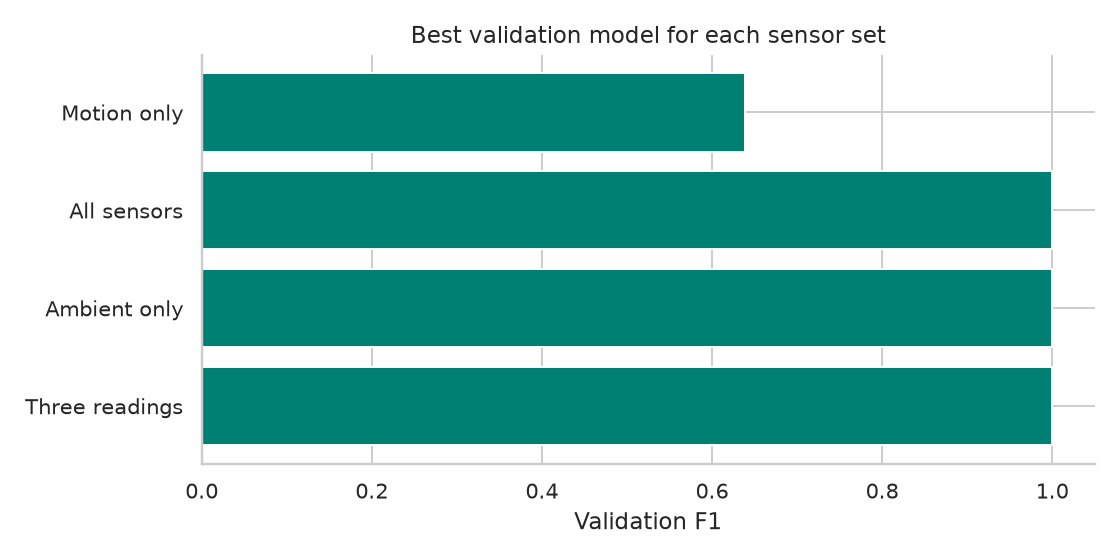

,sensor,f1_decrease,std
0,S1_Light,0.7187,0.0203
1,S1_Temp,0.0000,0.0000
2,S5_CO2,0.0000,0.0000


In [8]:
display(Image(filename=str(ROOT / 'reports/figures/sensor_comparison.png')))
importance = pd.read_csv(ROOT / 'reports/sensor_importance.csv')
display(importance.round(4))

## 8. Inference on a CSV

The saved pipeline preserves scaling and column order. Only source-compatible numeric sensor CSVs are accepted. The occupancy label is never an input. The app warns when input values fall outside the development-data range; being inside that range still does not guarantee validity in another room.

In [9]:
import joblib
from src.core import predict_frame
bundle = joblib.load(ROOT / 'artifacts/occupancy_model.joblib')
sample = pd.read_csv(ROOT / 'data/sample_upload.csv')
display(predict_frame(bundle, sample).head(10))

,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S6_PIR,S7_PIR,occupied_score,prediction,outside_training_range
0,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0,0,1.0,Occupied,False
1,25.44,25.56,24.94,25.88,155,236,71,54,1.53,1.24,0.36,0.27,500,1,0,1.0,Occupied,False
2,25.75,28.69,25.31,26.06,159,245,216,65,0.62,0.74,0.19,0.13,665,1,0,1.0,Occupied,False
3,26.06,27.06,26.00,26.25,165,255,275,70,0.42,0.33,1.04,0.09,910,1,1,1.0,Occupied,False
4,26.00,26.19,25.88,26.38,17,21,95,59,0.07,0.05,0.08,0.06,820,0,0,0.0,Empty,False
5,25.94,25.81,25.63,26.38,120,34,69,43,1.75,0.06,0.55,0.06,570,1,0,1.0,Occupied,False
6,26.06,25.69,25.56,26.38,115,25,38,21,0.26,0.10,0.06,0.07,630,1,0,1.0,Occupied,False
7,26.19,25.75,25.81,26.38,114,24,177,10,0.11,0.05,0.06,0.07,760,0,1,1.0,Occupied,False
8,26.31,26.38,26.00,26.38,148,235,179,10,0.10,0.05,0.07,0.06,1000,0,0,1.0,Occupied,False
9,26.31,28.00,26.06,26.44,150,239,181,11,1.26,0.30,1.74,0.21,1215,1,0,1.0,Occupied,False


## 9. Hypothetical energy scenario

Assume 300 W of equipment would otherwise be on during observed intervals, a five-minute vacancy review delay and an illustrative tariff of ₹8/kWh. These are assumptions, not source measurements. Integrate adjacent intervals only; gaps above 90 seconds reset the timer and contribute no energy. The final reading has no assumed duration. False-empty alert minutes are reported separately, because those intervals are not confirmed safe opportunities.

Potential kWh = eligible hours × assumed watts / 1000. Potential cost = kWh × assumed tariff.

In [10]:
predictions = pd.read_csv(ROOT / 'reports/test_predictions.csv', parse_dates=['timestamp'])
scenario = simulate_energy(predictions.timestamp, predictions.predicted_occupied,
                           watts=300, tariff=8, delay_minutes=5, truth=predictions.occupied)
display(pd.Series({k:v for k,v in scenario.items() if k != 'intervals'}, name='Scenario result'))

observed_hours                50.709444
eligible_hours                49.431389
potential_kwh                 14.829417
potential_cost               118.635333
false_empty_alert_minutes     89.966667
excluded_gaps                  2.000000
Name: Scenario result, dtype: float64

## 10. Conclusions and limitations

The executed results support a comparison of declared models and sensor sets within this dataset. The validation-selected model is reported independently on later records. A high accuracy is insufficient when most records are empty; occupied recall, F1 and false-empty counts must also be considered.

This is one controlled room, at most three people and a short, discontinuous recording. Sensor calibration and room conditions can change predictions. The simulation estimates conditional potential, not measured savings. No campus deployment, automatic control or actual hardware savings have been demonstrated.

See `reports/PROJECT_REPORT.md`, `reports/RESULTS.md` and `docs/VIVA_GUIDE.md` for the full project explanation. Dataset credit: Singh & Chaudhari, UCI Room Occupancy Estimation, https://doi.org/10.24432/C5P605, CC BY 4.0.